## 1. Import Libraries

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 5)
os.makedirs("../images", exist_ok=True)
os.makedirs("../models", exist_ok=True)
RANDOM_STATE = 42

## 2. Load the Dataset

In [4]:
df = pd.read_csv("student_data.csv")
df.head()

,student_id,gender,study_hours,attendance,previous_score,sleep_hours,assignments_completed,parental_education,internet_access,extracurricular,tutoring,final_score
0,1,Male,NaN,NaN,51.8,NaN,0,Master,Yes,No,No,76.1
1,2,Female,4.2,81.4,68.3,8.3,5,Bachelor,Yes,Yes,Yes,73.1
2,3,Female,5.2,NaN,64.5,8.7,4,Master,Yes,Yes,No,76.2
3,4,Male,3.9,89.3,63.5,8.1,10,NaN,Yes,Yes,Yes,79.8
4,5,Male,3.7,70.3,63.3,8.4,0,Bachelor,Yes,Yes,No,61.9


## 3. Understand the Data
| Column | Meaning |
|---|---|
| student_id | Unique ID (not useful for prediction) |
| gender | Male / Female |
| study_hours | Daily self-study hours |
| attendance | Attendance percentage |
| previous_score | Marks in the previous exam |
| sleep_hours | Average sleep per night |
| assignments_completed | Assignments done (out of 10) |
| parental_education | Highest parent education level |
| internet_access | Internet at home? |
| extracurricular | Takes part in activities? |
| tutoring | Extra tutoring? |
| **final_score** | **Target: final exam score** |

In [5]:
print("Shape:", df.shape)
df.info()

Shape: (1008, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             1008 non-null   int64  
 1   gender                 1008 non-null   object 
 2   study_hours            968 non-null    float64
 3   attendance             968 non-null    float64
 4   previous_score         967 non-null    float64
 5   sleep_hours            968 non-null    float64
 6   assignments_completed  1008 non-null   int64  
 7   parental_education     968 non-null    object 
 8   internet_access        1008 non-null   object 
 9   extracurricular        1008 non-null   object 
 10  tutoring               1008 non-null   object 
 11  final_score            1008 non-null   float64
dtypes: float64(5), int64(2), object(5)
memory usage: 94.6+ KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
student_id,1008.0,500.888889,288.573758,1.0,251.750,500.5,751.250,1000.0
study_hours,968.0,3.940702,1.969477,0.0,2.600,4.0,5.200,10.4
attendance,968.0,78.550826,11.573470,43.2,70.775,79.4,86.925,100.0
previous_score,967.0,65.479938,14.788383,22.1,55.200,65.4,76.200,100.0
sleep_hours,968.0,7.019525,1.260916,3.6,6.100,7.0,7.800,10.0
assignments_completed,1008.0,4.928571,3.054106,0.0,2.000,5.0,7.000,10.0
final_score,1008.0,72.573413,10.264973,32.0,65.500,72.8,79.900,100.0


## 4. Data Cleaning

### 4.1 Missing values

In [7]:
missing = df.isnull().sum()
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})

,missing,percent
student_id,0,0.00
gender,0,0.00
study_hours,40,3.97
attendance,40,3.97
previous_score,41,4.07
sleep_hours,40,3.97
assignments_completed,0,0.00
parental_education,40,3.97
internet_access,0,0.00
extracurricular,0,0.00


### 4.2 Duplicates

In [8]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 8
Shape after removing duplicates: (1000, 12)


### 4.3 Handle missing values
- **Numeric** columns → fill with **median** (robust to outliers)
- **Categorical** columns → fill with **mode** (most frequent)

> For the final model we do this inside a `Pipeline` (Section 8) so imputation is learned **only from training data** (avoids data leakage). Here we also clean the DataFrame so EDA works.

In [9]:
df_clean = df.drop(columns=["student_id"]).copy()

num_cols_all = df_clean.select_dtypes(include=np.number).columns.drop("final_score")
cat_cols_all = df_clean.select_dtypes(exclude=np.number).columns

for c in num_cols_all:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())
for c in cat_cols_all:
    df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])

print("Missing values left:", df_clean.isnull().sum().sum())

Missing values left: 0


### 4.4 Check outliers (IQR method)

In [10]:
for c in list(num_cols_all) + ["final_score"]:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df_clean[c] < q1 - 1.5 * iqr) | (df_clean[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c:25s} outliers: {n_out}")

study_hours               outliers: 4
attendance                outliers: 5
previous_score            outliers: 4
sleep_hours               outliers: 3
assignments_completed     outliers: 0
final_score               outliers: 4


### 4.5 Validate value ranges

In [11]:
assert df_clean["attendance"].between(0, 100).all()
assert df_clean["final_score"].between(0, 100).all()
assert df_clean["study_hours"].between(0, 24).all()
print("✅ Value ranges look valid")

✅ Value ranges look valid


## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribution of the target

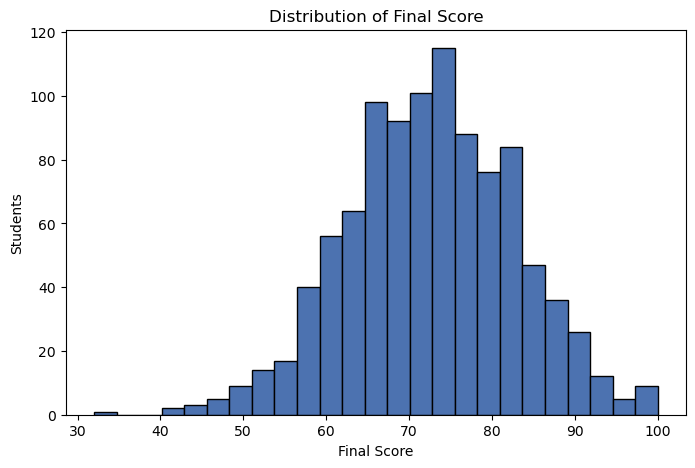

In [12]:
plt.hist(df_clean["final_score"], bins=25, edgecolor="black", color="#4C72B0")
plt.title("Distribution of Final Score"); plt.xlabel("Final Score"); plt.ylabel("Students")
plt.savefig("../images/01_score_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.2 Distribution of numeric features

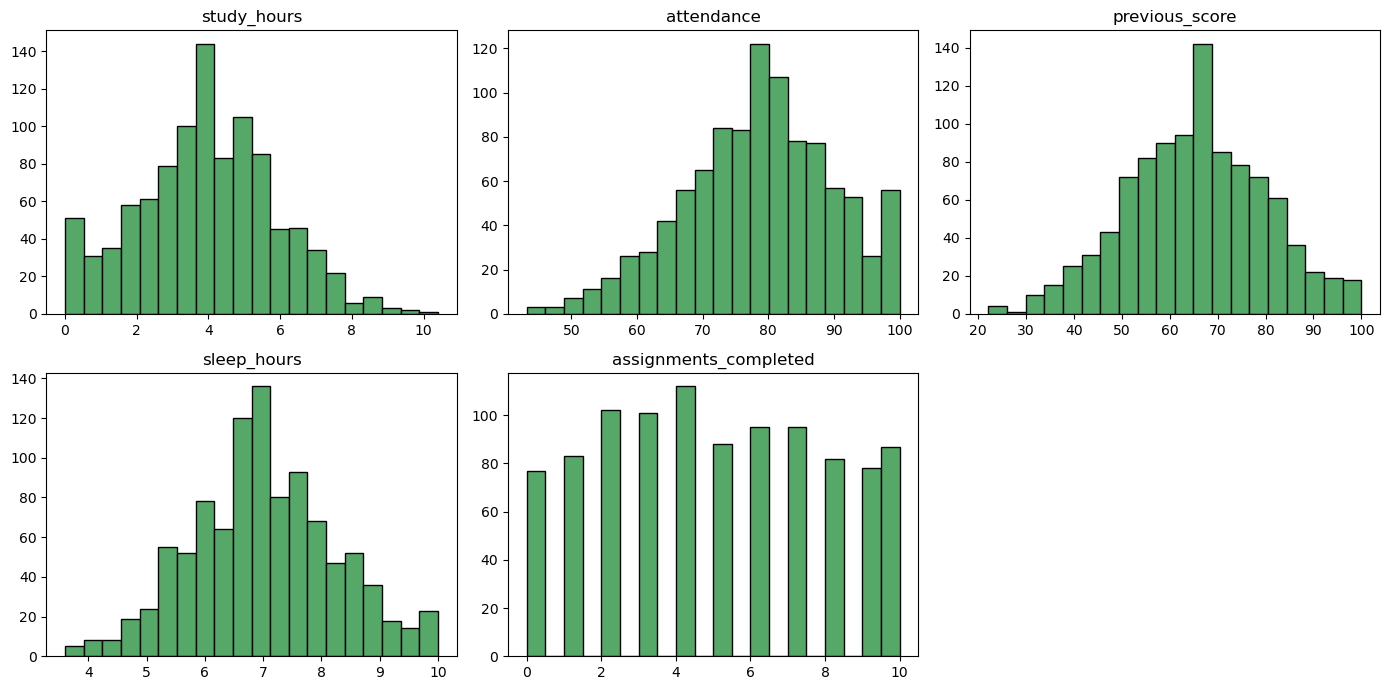

In [13]:
num_cols = ["study_hours", "attendance", "previous_score", "sleep_hours", "assignments_completed"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(df_clean[c], bins=20, edgecolor="black", color="#55A868"); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("../images/02_feature_distributions.png", dpi=150); plt.show()

### 5.3 Relationship of features with final score

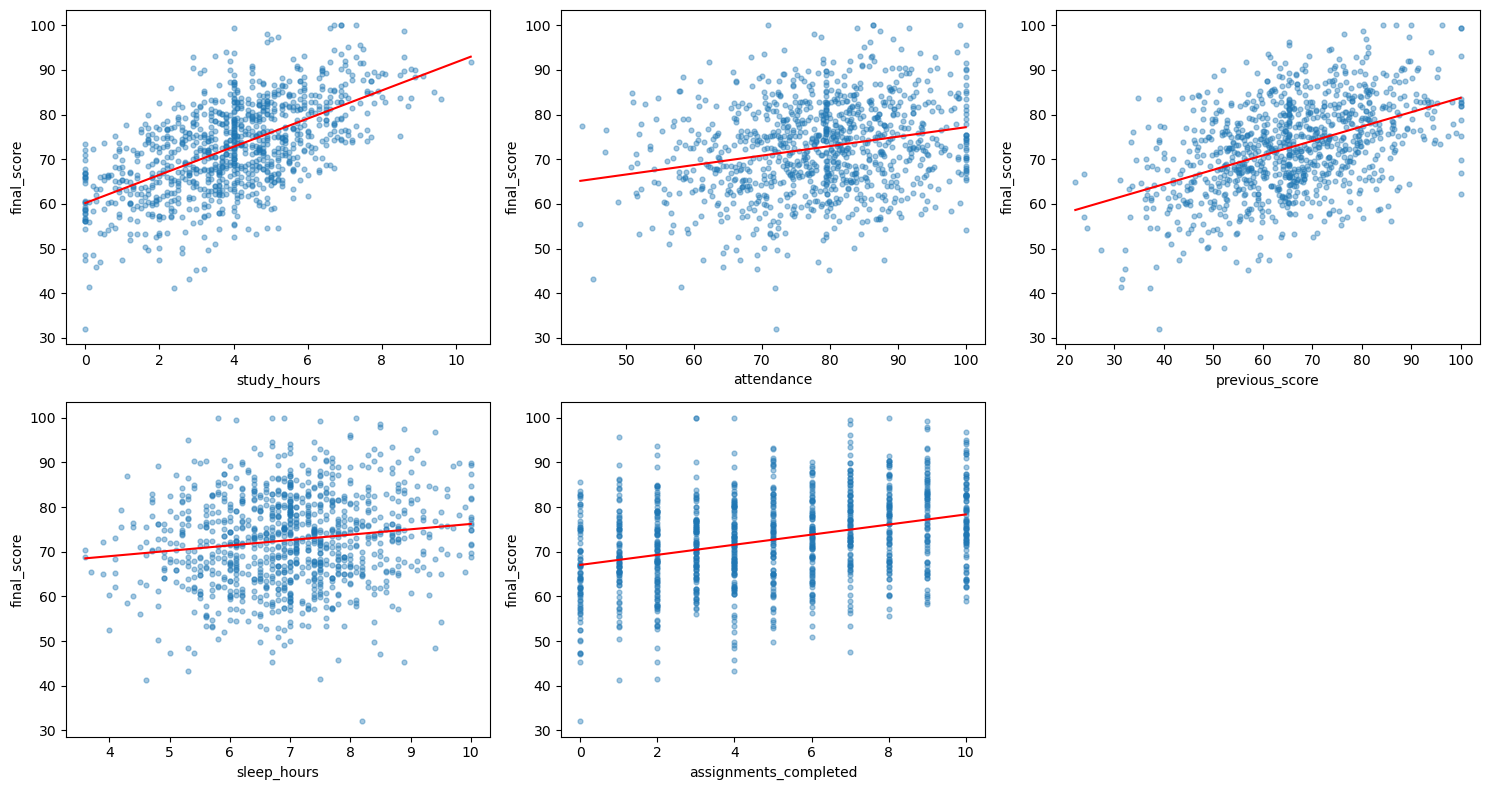

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols):
    ax.scatter(df_clean[c], df_clean["final_score"], alpha=0.4, s=12)
    m, b = np.polyfit(df_clean[c], df_clean["final_score"], 1)
    xs = np.linspace(df_clean[c].min(), df_clean[c].max(), 50)
    ax.plot(xs, m * xs + b, color="red"); ax.set_xlabel(c); ax.set_ylabel("final_score")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("../images/03_scatter_vs_score.png", dpi=150); plt.show()

### 5.4 Categorical features vs. average score

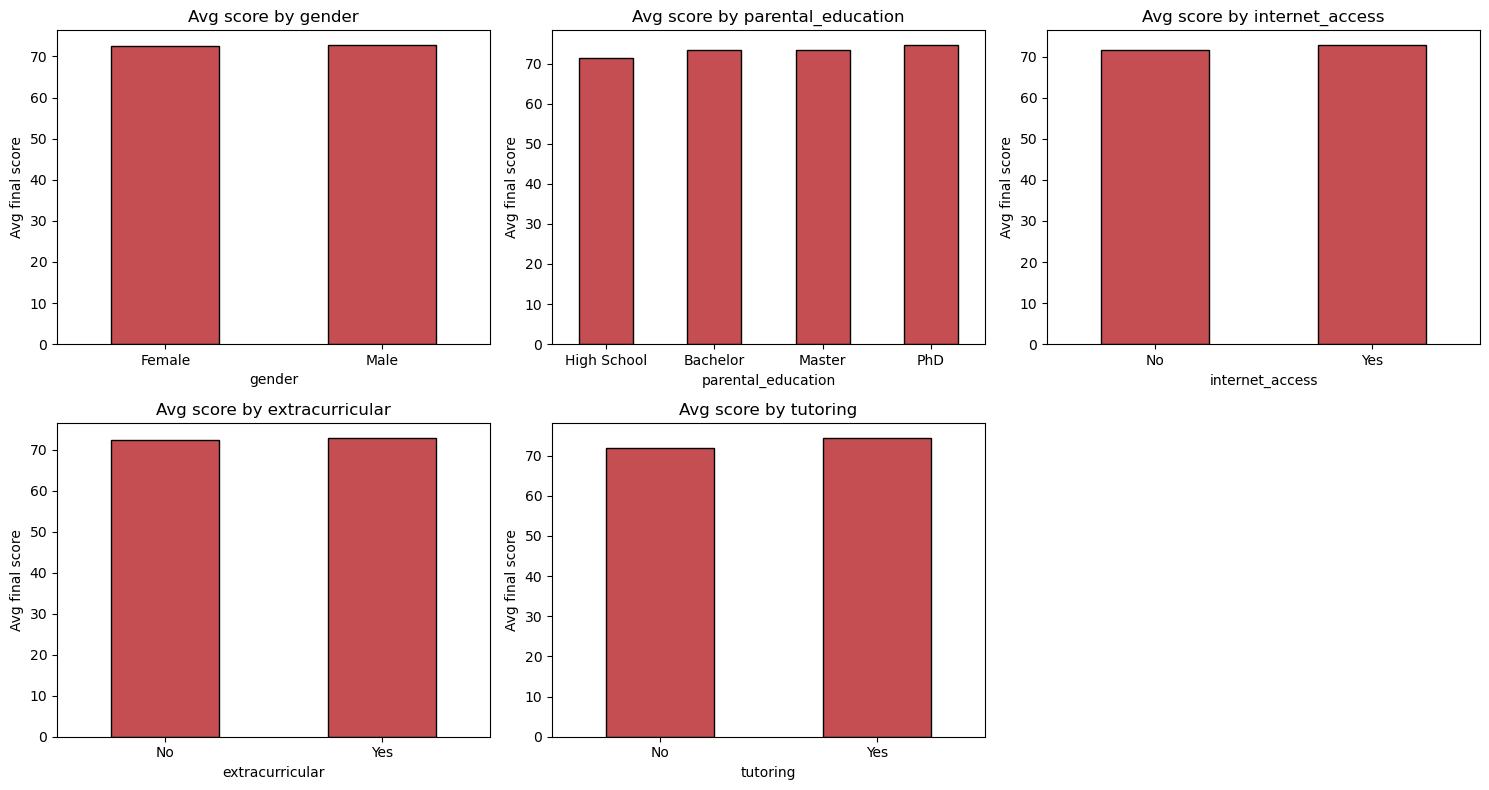

In [15]:
cat_cols = ["gender", "parental_education", "internet_access", "extracurricular", "tutoring"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    df_clean.groupby(c)["final_score"].mean().sort_values().plot(kind="bar", ax=ax, color="#C44E52", edgecolor="black")
    ax.set_title(f"Avg score by {c}"); ax.set_ylabel("Avg final score"); ax.tick_params(axis="x", rotation=0)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("../images/04_categorical_vs_score.png", dpi=150); plt.show()

### 5.5 Correlation heatmap

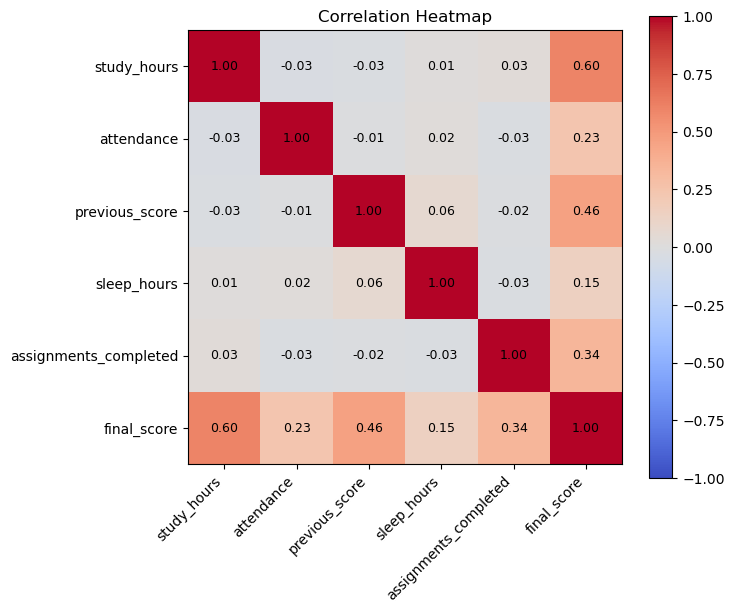

In [16]:
corr = df_clean[num_cols + ["final_score"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im); plt.title("Correlation Heatmap")
plt.savefig("../images/05_correlation_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

In [17]:
print("Correlation with final_score:")
corr["final_score"].drop("final_score").sort_values(ascending=False)

Correlation with final_score:


study_hours              0.595136
previous_score           0.457330
assignments_completed    0.338306
attendance               0.234691
sleep_hours              0.145624
Name: final_score, dtype: float64

### 5.6 Key insights (write these in your report)
- `study_hours`, `previous_score`, `assignments_completed` and `attendance` show the strongest positive relationship with the final score.
- Students with tutoring and internet access score slightly higher on average.
- `gender` and `extracurricular` show little difference.

## 6. Feature Selection

We combine **correlation** and **mutual information** to judge feature importance.

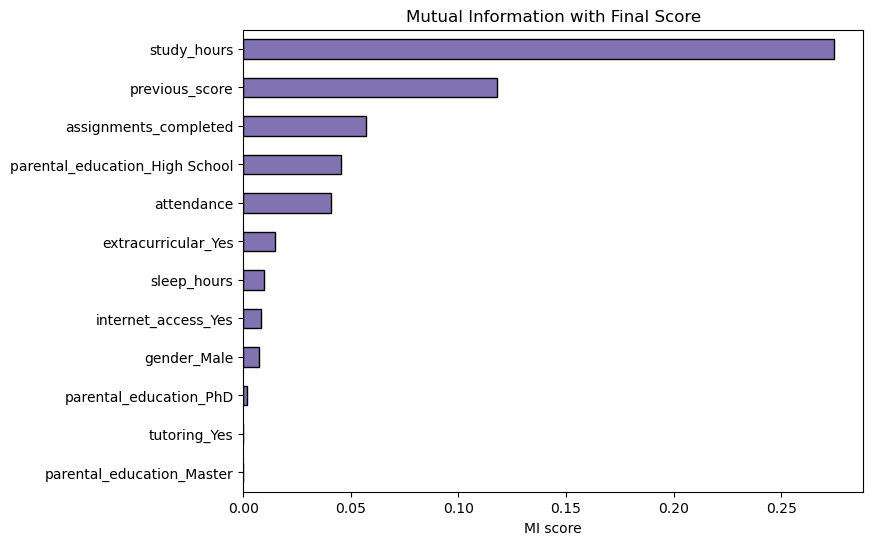

In [18]:
from sklearn.feature_selection import mutual_info_regression

X_tmp = pd.get_dummies(df_clean.drop(columns=["final_score"]), drop_first=True)
mi = pd.Series(mutual_info_regression(X_tmp, df_clean["final_score"], random_state=RANDOM_STATE),
               index=X_tmp.columns).sort_values()
mi.plot(kind="barh", figsize=(8, 6), color="#8172B2", edgecolor="black")
plt.title("Mutual Information with Final Score"); plt.xlabel("MI score")
plt.savefig("../images/06_feature_importance_mi.png", dpi=150, bbox_inches="tight"); plt.show()

**Decision:** keep all features except `student_id` (an identifier). Weak features (e.g. gender) are retained because they are harmless for tree models; you may experiment with dropping them and compare scores.

## 7. Train / Test Split

In [19]:
FEATURES_NUM = ["study_hours", "attendance", "previous_score", "sleep_hours", "assignments_completed"]
FEATURES_CAT = ["gender", "parental_education", "internet_access", "extracurricular", "tutoring"]

# Use the ORIGINAL (de-duplicated, un-imputed) data so the pipeline learns imputation from train only
data = df.drop(columns=["student_id"])
X = data[FEATURES_NUM + FEATURES_CAT]
y = data["final_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 10)  Test: (200, 10)


## 8. Preprocessing Pipeline + Model Training

Preprocessing steps:
- **Numeric:** median imputation → standard scaling
- **Categorical:** most-frequent imputation → one-hot encoding

In [20]:
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([("num", numeric_pipe, FEATURES_NUM),
                                  ("cat", categorical_pipe, FEATURES_CAT)])

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results = []
fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2").mean()
    results.append({"Model": name,
                    "MAE": mean_absolute_error(y_test, pred),
                    "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                    "R2 (test)": r2_score(y_test, pred),
                    "R2 (5-fold CV)": cv})
    fitted[name] = pipe

results_df = pd.DataFrame(results).sort_values("R2 (test)", ascending=False).round(4)
results_df

,Model,MAE,RMSE,R2 (test),R2 (5-fold CV)
0,Linear Regression,3.6020,4.5593,0.7794,0.7984
2,Gradient Boosting,3.9715,5.0357,0.7309,0.7464
1,Random Forest,4.1583,5.3453,0.6968,0.7309


## 9. Evaluation

In [21]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)
print(f"Best model: {best_name}")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R²  : {r2_score(y_test, y_pred):.3f}")

Best model: Linear Regression
MAE : 3.60
RMSE: 4.56
R²  : 0.779


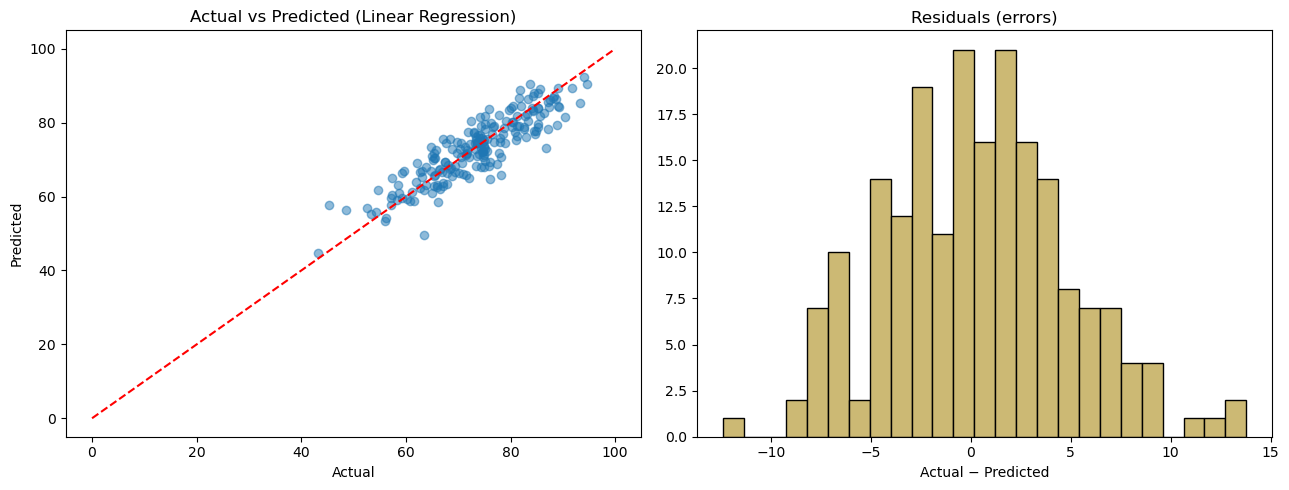

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, alpha=0.5)
axes[0].plot([0, 100], [0, 100], "r--"); axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Actual vs Predicted ({best_name})")

residuals = y_test - y_pred
axes[1].hist(residuals, bins=25, edgecolor="black", color="#CCB974")
axes[1].set_title("Residuals (errors)"); axes[1].set_xlabel("Actual − Predicted")
plt.tight_layout(); plt.savefig("../images/07_actual_vs_predicted.png", dpi=150); plt.show()

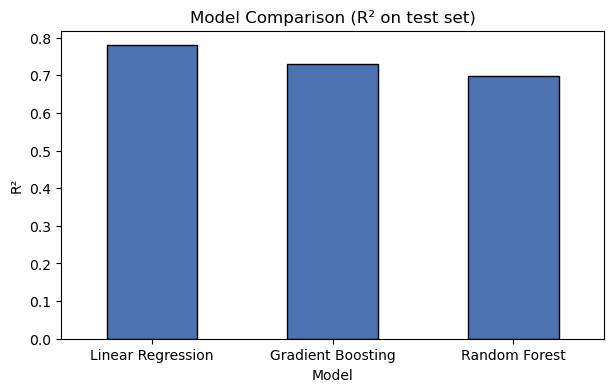

In [23]:
# Model comparison chart
results_df.set_index("Model")["R2 (test)"].plot(kind="bar", color="#4C72B0", edgecolor="black", figsize=(7, 4))
plt.title("Model Comparison (R² on test set)"); plt.ylabel("R²"); plt.xticks(rotation=0)
plt.savefig("../images/08_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Improve the Model (Hyperparameter Tuning)

In [24]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("prep", preprocessor), ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])
param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
tuned_pred = grid.predict(X_test)
print(f"Tuned R²: {r2_score(y_test, tuned_pred):.3f} | MAE: {mean_absolute_error(y_test, tuned_pred):.2f}")

Best params: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}
Tuned R²: 0.749 | MAE: 3.78


In [25]:
# Pick the overall winner between the earlier best model and the tuned model
final_model = grid.best_estimator_ if r2_score(y_test, tuned_pred) >= r2_score(y_test, y_pred) else best_model
final_pred = final_model.predict(X_test)
print("Final R²:", round(r2_score(y_test, final_pred), 3))

Final R²: 0.779


### Feature importance of the final model

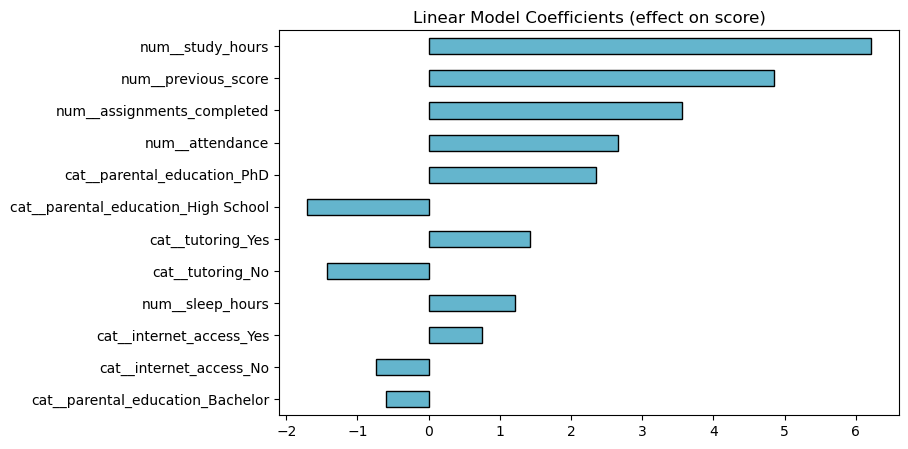

Final model used: LinearRegression


In [26]:
model_step = final_model.named_steps["model"]
names = final_model.named_steps["prep"].get_feature_names_out()
if hasattr(model_step, "feature_importances_"):          # tree models
    imp = pd.Series(model_step.feature_importances_, index=names); title = "Top Feature Importances"
else:                                                     # linear model -> coefficients (features are scaled)
    imp = pd.Series(model_step.coef_, index=names); title = "Linear Model Coefficients (effect on score)"
imp = imp.loc[imp.abs().sort_values().index]
imp.tail(12).plot(kind="barh", figsize=(8, 5), color="#64B5CD", edgecolor="black")
plt.title(title); plt.savefig("../images/09_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
print("Final model used:", type(model_step).__name__)

## 11. Save the Model

In [27]:
joblib.dump(final_model, "../models/student_model.pkl")
results_df.to_csv("../reports/model_results.csv", index=False)
print("✅ Model saved to ../models/student_model.pkl")

✅ Model saved to ../models/student_model.pkl


## 12. Prediction System

In [28]:
def performance_level(score):
    if score >= 85: return "Excellent 🌟"
    if score >= 70: return "Good 👍"
    if score >= 50: return "Average 📘"
    return "Poor ⚠️"

def predict_student(study_hours, attendance, previous_score, sleep_hours, assignments_completed,
                    gender, parental_education, internet_access, extracurricular, tutoring):
    model = joblib.load("../models/student_model.pkl")
    row = pd.DataFrame([{
        "study_hours": study_hours, "attendance": attendance, "previous_score": previous_score,
        "sleep_hours": sleep_hours, "assignments_completed": assignments_completed,
        "gender": gender, "parental_education": parental_education,
        "internet_access": internet_access, "extracurricular": extracurricular, "tutoring": tutoring,
    }])
    score = float(np.clip(model.predict(row)[0], 0, 100))
    return round(score, 1), performance_level(score)

# Example
score, level = predict_student(6, 90, 75, 7, 9, "Female", "Bachelor", "Yes", "Yes", "No")
print(f"Predicted Final Score: {score}  →  {level}")

Predicted Final Score: 89.0  →  Excellent 🌟
